<a href="https://colab.research.google.com/github/DanisStepanov/Computer-mathematics-systems/blob/main/_____9_____yolov12___________.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# **Практическая работа №9. Использование модели YOLOv26 для решение задач детекции и классификации**

## **Задание 1. Знакомство с новейшей версией модели YOLO**

- Ознакомьтесь с технической документацией по новейшей версии модели YOLOv26: https://docs.ultralytics.com/ru/models/yolo26/

- Рассмотрите пример обучения этой модели c использованием датасетов, созданных в Roboflow: https://colab.research.google.com/github/roboflow-ai/notebooks/blob/main/notebooks/train-yolo26-object-detection-on-custom-dataset.ipynb?ref=blog.roboflow.com

### **Ответьте на вопрос: Какие принципиальные отличия появились в модели YOLOv26 относительно предыдущих версий?**

**ВАШ ОТВЕТ**

*Примечание:* для каждого последующего задания, в конечном итоге, необходимо сформировать обученную модель и задеплоить её на сервисе **RoboFlow**



## **Задание 2. Найдите готовый датасет для детекции объектов и обучите на нем модель YOLOv26:**

- Для удобства работы с датасетом и деплоя модели используйте сервис [RoboFlow](https://roboflow.com/)

In [ ]:
!pip install -q -U ultralytics roboflow supervision inference pycuda Pillow

# Подавляем предупреждения для чистоты вывода
import warnings
warnings.filterwarnings('ignore')

In [24]:
!nvidia-smi

Thu Nov 12 02:22:44 2026       
+-----------------------------------------------------------------------------------------+
| NVIDIA-SMI 580.82.07              Driver Version: 580.82.07      CUDA Version: 13.0     |
+-----------------------------------------+------------------------+----------------------+
| GPU  Name                 Persistence-M | Bus-Id          Disp.A | Volatile Uncorr. ECC |
| Fan  Temp   Perf          Pwr:Usage/Cap |           Memory-Usage | GPU-Util  Compute M. |
|                                         |                        |               MIG M. |
|=========================================+========================+======================|
|   0  Tesla T4                       Off |   00000000:00:04.0 Off |                    0 |
| N/A   72C    P0             30W /   70W |    2121MiB /  15360MiB |      0%      Default |
|                                         |                        |                  N/A |
+-----------------------------------------+-----

In [25]:
# Импорт библиотек и проверка версий
import torch
import numpy as np
from ultralytics import YOLO

print(f"PyTorch version: {torch.__version__}")
print(f"NumPy version: {np.__version__}")
print(f"CUDA available: {torch.cuda.is_available()}")

# Если CUDA доступна, выводим информацию о GPU
if torch.cuda.is_available():
    print(f"GPU: {torch.cuda.get_device_name(0)}")
    print(f"CUDA version: {torch.version.cuda}")

PyTorch version: 2.14.1+cu130
NumPy version: 2.2.6
CUDA available: True
GPU: Tesla T4
CUDA version: 13.0


In [26]:
import os
from pathlib import Path

# Определяем домашнюю директорию проекта
HOME = Path.cwd()
print(f"Рабочая директория: {HOME}")

# Создаём необходимые поддиректории
WEIGHTS_DIR = HOME / "weights1"
DATA_DIR = HOME / "data1"
RESULTS_DIR = HOME / "results1"

# Создаём директории, если они не существуют
for directory in [WEIGHTS_DIR, DATA_DIR, RESULTS_DIR]:
    directory.mkdir(parents=True, exist_ok=True)
    print(f"Директория создана: {directory}")

Рабочая директория: /content
Директория создана: /content/weights1
Директория создана: /content/data1
Директория создана: /content/results1


In [27]:
import roboflow

# Авторизация в Roboflow
# При выполнении откроется ссылка для получения API-ключа
roboflow.login()

# Создание клиента Roboflow
rf = roboflow.Roboflow()

You are already logged into Roboflow. To make a different login,run roboflow.login(force=True).


In [28]:
# Подключение к рабочему пространству и проекту
# Замените 'alexandre-b2d69' и 'first-ugfem' на ваши значения
WORKSPACE_NAME = "usna-dcxiv"  # Имя рабочего пространства
PROJECT_NAME = "ships-4od7b"        # Имя проекта

# Получаем доступ к проекту
project = rf.workspace(WORKSPACE_NAME).project(PROJECT_NAME)

# Просмотр доступных версий датасета
print("Доступные версии датасета:")
project.list_versions()

loading Roboflow workspace...
loading Roboflow project...
Доступные версии датасета:
[{'id': 'usna-dcxiv/ships-4od7b/15', 'name': '2023-02-02 9:31am', 'created': 1675348296.285, 'images': 5960, 'splits': {'valid': 498, 'test': 279, 'train': 5183}, 'generating': False, 'progress': 1, 'preprocessing': {'isolate': True, 'auto-orient': True, 'resize': {'format': 'Stretch to', 'width': '600', 'height': '416'}, 'remap': {'labels': {'DDG': {'omit': True}, 'Aircraft Carrier': {'omit': True}, 'Submarine': {'omit': True}}}}, 'augmentation': {'image': {'versions': 3}, 'blur': {'pixels': 3.75}, 'flip': {'horizontal': True, 'vertical': False}}, 'exports': ['coco', 'darknet', 'voc', 'yolo26', 'yolokeras', 'yolov11', 'yolov12', 'yolov5pytorch', 'yolov7pytorch', 'yolov8', 'yolov9']}, {'id': 'usna-dcxiv/ships-4od7b/14', 'name': 'no mil', 'created': 1657649785.907, 'images': 8520, 'splits': {'valid': 692, 'test': 387, 'train': 7441}, 'generating': False, 'progress': 1, 'model': {'id': 'ships-4od7b/14', 

In [33]:
# Загрузка конкретной версии датасета
VERSION_NUMBER = 15

version = project.version(VERSION_NUMBER)
dataset = version.download("yolov8")

# Вывод информации о загруженном датасете
print(f"\nДатасет загружен в: {dataset.location}")
print(f"Путь к конфигурации: {dataset.location}/data.yaml")


Датасет загружен в: /content/Ships-15
Путь к конфигурации: /content/Ships-15/data.yaml


In [34]:
import yaml
from pathlib import Path

# Чтение конфигурационного файла датасета
data_yaml_path = Path(dataset.location) / "data.yaml"

with open(data_yaml_path, 'r') as f:
    data_config = yaml.safe_load(f)

print("Конфигурация датасета:")
print("-" * 50)
print(f"Обучающая выборка: {data_config.get('train', 'не указана')}")
print(f"Валидационная выборка: {data_config.get('val', 'не указана')}")
print(f"Тестовая выборка: {data_config.get('test', 'не указана')}")
print(f"\nКлассы ({data_config.get('nc', 0)} шт.):")

for idx, class_name in enumerate(data_config.get('names', [])):
    print(f"  {idx}: {class_name}")

Конфигурация датасета:
--------------------------------------------------
Обучающая выборка: ../train/images
Валидационная выборка: ../valid/images
Тестовая выборка: ../test/images

Классы (7 шт.):
  0: Bulkers
  1: Car Carrier
  2: Container Ship
  3: Cruise
  4: Recreational
  5: Sailboat
  6: Tug


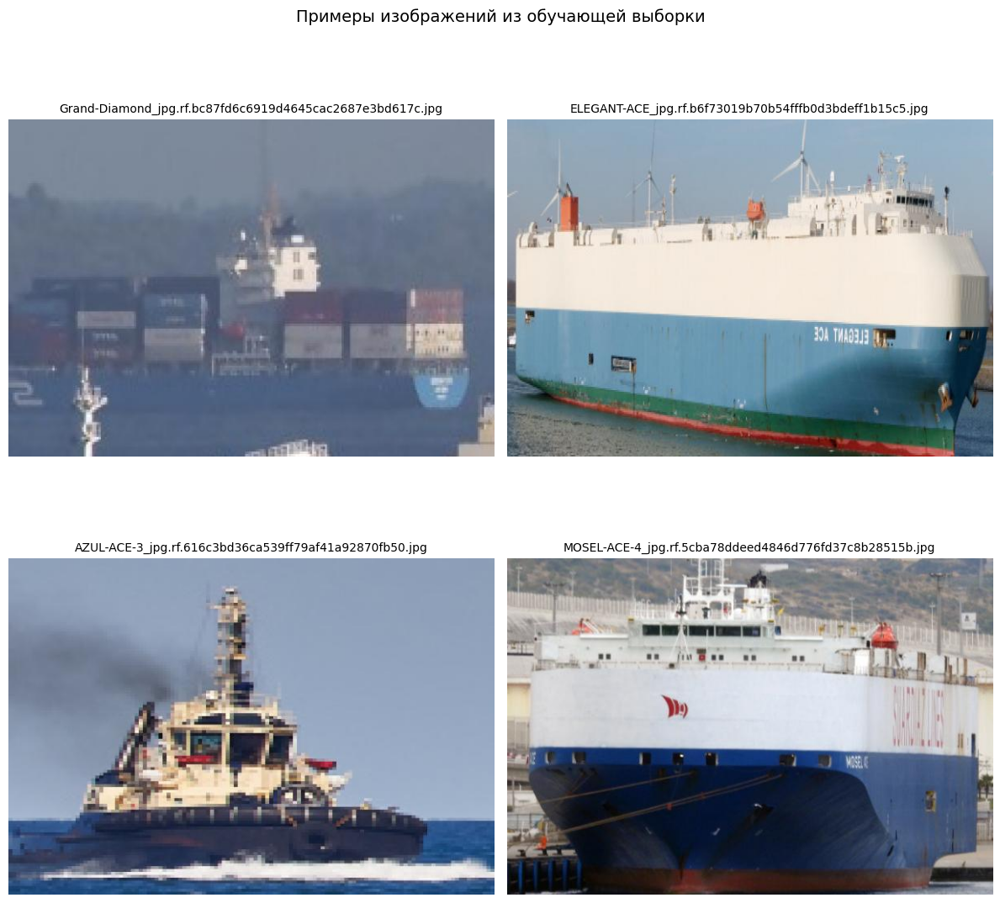

In [35]:
import random
from PIL import Image
import matplotlib.pyplot as plt

def visualize_dataset_samples(dataset_path, num_samples=4):
    """
    Отображает случайные примеры из датасета.

    Args:
        dataset_path: путь к датасету
        num_samples: количество примеров для отображения
    """
    # Находим изображения в обучающей выборке
    train_images_path = Path(dataset_path) / "train" / "images"
    image_files = list(train_images_path.glob("*.jpg")) + list(train_images_path.glob("*.png"))

    if not image_files:
        print("Изображения не найдены!")
        return

    # Выбираем случайные изображения
    selected = random.sample(image_files, min(num_samples, len(image_files)))

    # Создаём сетку для отображения
    cols = 2
    rows = (num_samples + 1) // 2
    fig, axes = plt.subplots(rows, cols, figsize=(12, 6*rows))
    axes = axes.flatten() if num_samples > 1 else [axes]

    for ax, img_path in zip(axes, selected):
        img = Image.open(img_path)
        ax.imshow(img)
        ax.set_title(img_path.name, fontsize=10)
        ax.axis('off')

    # Скрываем пустые оси
    for ax in axes[len(selected):]:
        ax.axis('off')

    plt.suptitle('Примеры изображений из обучающей выборки', fontsize=14)
    plt.tight_layout()
    plt.show()

# Визуализация примеров
visualize_dataset_samples(dataset.location)

In [36]:
import os

# Отключаем внешние логгеры для чистоты вывода
os.environ["WANDB_MODE"] = "disabled"
os.environ["WANDB_SILENT"] = "true"
os.environ["CLEARML_DISABLE"] = "1"
os.environ["COMET_DISABLE"] = "1"

In [37]:
# Словарь с параметрами обучения
TRAINING_CONFIG = {
    # Основные параметры
    'data': f"{dataset.location}/data.yaml",  # Путь к конфигурации датасета
    'epochs': 80,                              # Количество эпох обучения
    'batch': 16,                               # Размер батча
    'imgsz': 640,                              # Размер входного изображения
    'device': 0,                               # GPU устройство (0 = первый GPU)

    # Параметры оптимизации
    'optimizer': 'auto',                       # Оптимизатор (auto, SGD, Adam, AdamW)
    'lr0': 0.001,                               # Начальная скорость обучения
    'lrf': 0.01,                               # Финальная скорость обучения (lr0 * lrf)
    'momentum': 0.937,                         # Момент для SGD
    'weight_decay': 0.001,                    # L2 регуляризация

    # Аугментации
    'hsv_h': 0.015,                            # Аугментация оттенка
    'hsv_s': 0.7,                              # Аугментация насыщенности
    'hsv_v': 0.4,                              # Аугментация яркости
    'degrees': 0.0,                            # Диапазон поворота
    'translate': 0.1,                          # Диапазон сдвига
    'scale': 0.5,                              # Диапазон масштабирования
    'fliplr': 0.5,                             # Вероятность горизонтального отражения
    'mosaic': 1.0,                             # Вероятность мозаичной аугментации

    # Дополнительные параметры
    'close_mosaic': 15,                        # Отключить мозаику за N эпох до конца
    'patience': 50,                            # Ранняя остановка (эпох без улучшения)
    'save': True,                              # Сохранять чекпоинты
    'save_period': -1,                         # Сохранять каждые N эпох (-1 = только лучшую)
    'verbose': True,                           # Подробный вывод
    'project': str(RESULTS_DIR),               # Директория для результатов
    'name': 'train_yolo26',                    # Имя эксперимента
    'exist_ok': True,                          # Перезаписывать существующую директорию
}

print("Конфигурация обучения:")
print("-" * 50)
for key, value in TRAINING_CONFIG.items():
    print(f"{key:20}: {value}")

Конфигурация обучения:
--------------------------------------------------
data                : /content/Ships-15/data.yaml
epochs              : 80
batch               : 16
imgsz               : 640
device              : 0
optimizer           : auto
lr0                 : 0.001
lrf                 : 0.01
momentum            : 0.937
weight_decay        : 0.001
hsv_h               : 0.015
hsv_s               : 0.7
hsv_v               : 0.4
degrees             : 0.0
translate           : 0.1
scale               : 0.5
fliplr              : 0.5
mosaic              : 1.0
close_mosaic        : 15
patience            : 50
save                : True
save_period         : -1
verbose             : True
project             : /content/results1
name                : train_yolo26
exist_ok            : True


In [38]:
from ultralytics import YOLO

# Загрузка базовой модели для дообучения (transfer learning)
# Используем предобученные веса yolov9c
model = YOLO('yolo26s.pt')

# Запуск обучения с заданными параметрами
# Метод train() возвращает объект с результатами обучения
results = model.train(**TRAINING_CONFIG)

print("\n" + "=" * 50)
print("Обучение завершено!")
print(f"Результаты сохранены в: {results.save_dir}")

Ultralytics 8.4.211 🚀 Python-3.13.16 torch-2.14.1+cu130 CUDA:0 (Tesla T4, 14913MiB)
engine/trainer: agnostic_nms=False, amp=True, angle=1.0, augment=False, auto_augment=randaugment, batch=16, bgr=0.0, box=7.5, cache=False, cfg=None, channels_last=None, classes=None, close_mosaic=15, cls=0.5, cls_pw=0.0, cls_remap=True, compile=False, conf=None, copy_paste=0.0, copy_paste_mode=flip, cos_lr=False, cutmix=0.0, data=/content/Ships-15/data.yaml, degrees=0.0, deterministic=True, device=0, dfl=1.5, dgrad=0.5, dis=6.0, distill_model=None, dlam=1.0, dlog=1.0, dnn=False, dropout=0.0, dynamic=False, embed=None, epochs=80, erasing=0.4, exist_ok=True, fliplr=0.5, flipud=0.0, format=torchscript, fraction=1.0, freeze=None, hsv_h=0.015, hsv_s=0.7, hsv_v=0.4, imgsz=640, iou=None, kobj=1.0, line_width=None, lr0=0.001, lrf=0.01, mask_ratio=4, max_det=300, mixup=0.0, mode=train, model=yolo26s.pt, momentum=0.937, mosaic=1.0, multi_scale=0.0, name=train_yolo26, nbs=64, nms=None, opset=None, optimize=False, 

## **Задание 3. Сформируйте свой датасет для детекции объектов и обучите на нем модель YOLOv26**



Требования к датасету:

- Количество изображений в датасете: минимум 90
- Количество классов: более 2х
- Обязательно должны присутствовать изображения, содержащие несколько классов одновременно


*Примечание: Формирование датасета включает в себя поиск изображений и ручное аннотирование объектов на изображениях.*

In [1]:
!nvidia-smi

Thu Nov 12 01:45:02 2026       
+-----------------------------------------------------------------------------------------+
| NVIDIA-SMI 580.82.07              Driver Version: 580.82.07      CUDA Version: 13.0     |
+-----------------------------------------+------------------------+----------------------+
| GPU  Name                 Persistence-M | Bus-Id          Disp.A | Volatile Uncorr. ECC |
| Fan  Temp   Perf          Pwr:Usage/Cap |           Memory-Usage | GPU-Util  Compute M. |
|                                         |                        |               MIG M. |
|=========================================+========================+======================|
|   0  Tesla T4                       Off |   00000000:00:04.0 Off |                    0 |
| N/A   40C    P8             10W /   70W |       0MiB /  15360MiB |      0%      Default |
|                                         |                        |                  N/A |
+-----------------------------------------+-----

In [3]:
# Импорт библиотек и проверка версий
import torch
import numpy as np
from ultralytics import YOLO

print(f"PyTorch version: {torch.__version__}")
print(f"NumPy version: {np.__version__}")
print(f"CUDA available: {torch.cuda.is_available()}")

# Если CUDA доступна, выводим информацию о GPU
if torch.cuda.is_available():
    print(f"GPU: {torch.cuda.get_device_name(0)}")
    print(f"CUDA version: {torch.version.cuda}")

PyTorch version: 2.14.1+cu130
NumPy version: 2.2.6
CUDA available: True
GPU: Tesla T4
CUDA version: 13.0


In [4]:
import os
from pathlib import Path

# Определяем домашнюю директорию проекта
HOME = Path.cwd()
print(f"Рабочая директория: {HOME}")

# Создаём необходимые поддиректории
WEIGHTS_DIR = HOME / "weights"
DATA_DIR = HOME / "data"
RESULTS_DIR = HOME / "results"

# Создаём директории, если они не существуют
for directory in [WEIGHTS_DIR, DATA_DIR, RESULTS_DIR]:
    directory.mkdir(parents=True, exist_ok=True)
    print(f"Директория создана: {directory}")

Рабочая директория: /content
Директория создана: /content/weights
Директория создана: /content/data
Директория создана: /content/results


In [5]:
import roboflow

# Авторизация в Roboflow
# При выполнении откроется ссылка для получения API-ключа
roboflow.login()

# Создание клиента Roboflow
rf = roboflow.Roboflow()

visit https://app.roboflow.com/auth-cli to get your authentication token.
Paste the authentication token here: ··········


In [6]:
# Подключение к рабочему пространству и проекту
# Замените 'alexandre-b2d69' и 'first-ugfem' на ваши значения
WORKSPACE_NAME = "mydataset-obims"  # Имя рабочего пространства
PROJECT_NAME = "my-first-project-o5hld"        # Имя проекта

# Получаем доступ к проекту
project = rf.workspace(WORKSPACE_NAME).project(PROJECT_NAME)

# Просмотр доступных версий датасета
print("Доступные версии датасета:")
project.list_versions()

loading Roboflow workspace...
loading Roboflow project...
Доступные версии датасета:
[{'id': 'mydataset-obims/my-first-project-o5hld/1', 'name': '1.0', 'created': 1794434040.713, 'images': 122, 'splits': {'valid': 24, 'test': 13, 'train': 85}, 'generating': False, 'progress': 1, 'preprocessing': {'auto-orient': True, 'resize': {'format': 'Stretch to', 'width': '640', 'height': '640'}}, 'augmentation': {}, 'exports': []}]


In [7]:
# Загрузка конкретной версии датасета
VERSION_NUMBER = 1

version = project.version(VERSION_NUMBER)
dataset = version.download("yolov9")

# Вывод информации о загруженном датасете
print(f"\nДатасет загружен в: {dataset.location}")
print(f"Путь к конфигурации: {dataset.location}/data.yaml")

Exporting format yolov9 in progress : 65.0%
Version export complete for yolov9 format



Extracting Dataset Version Zip to My-First-Project-1 in yolov9:: 100%|██████████| 248/248 [00:00<00:00, 7268.29it/s]



Датасет загружен в: /content/My-First-Project-1
Путь к конфигурации: /content/My-First-Project-1/data.yaml


In [8]:
import yaml
from pathlib import Path

# Чтение конфигурационного файла датасета
data_yaml_path = Path(dataset.location) / "data.yaml"

with open(data_yaml_path, 'r') as f:
    data_config = yaml.safe_load(f)

print("Конфигурация датасета:")
print("-" * 50)
print(f"Обучающая выборка: {data_config.get('train', 'не указана')}")
print(f"Валидационная выборка: {data_config.get('val', 'не указана')}")
print(f"Тестовая выборка: {data_config.get('test', 'не указана')}")
print(f"\nКлассы ({data_config.get('nc', 0)} шт.):")

for idx, class_name in enumerate(data_config.get('names', [])):
    print(f"  {idx}: {class_name}")

Конфигурация датасета:
--------------------------------------------------
Обучающая выборка: ../train/images
Валидационная выборка: ../valid/images
Тестовая выборка: ../test/images

Классы (5 шт.):
  0: Building
  1: Creep
  2: Health scale
  3: Hero
  4: Tree


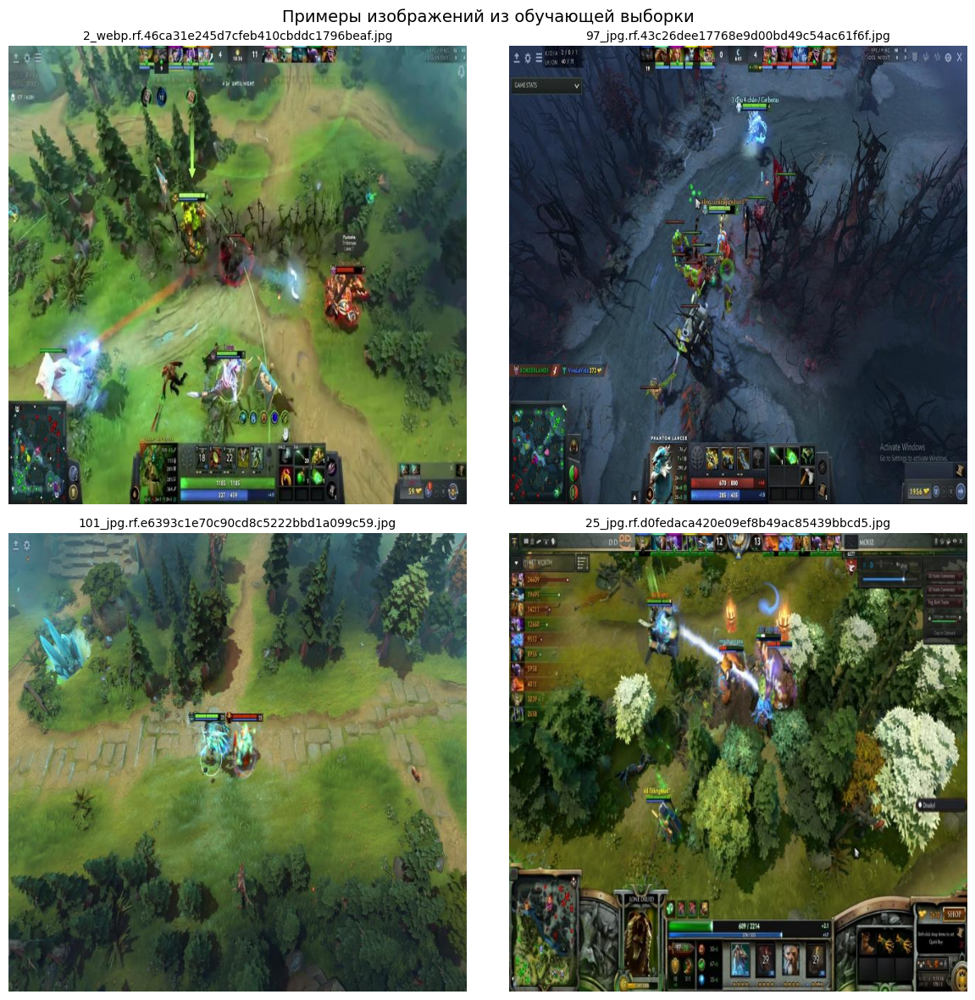

In [9]:
import random
from PIL import Image
import matplotlib.pyplot as plt

def visualize_dataset_samples(dataset_path, num_samples=4):
    """
    Отображает случайные примеры из датасета.

    Args:
        dataset_path: путь к датасету
        num_samples: количество примеров для отображения
    """
    # Находим изображения в обучающей выборке
    train_images_path = Path(dataset_path) / "train" / "images"
    image_files = list(train_images_path.glob("*.jpg")) + list(train_images_path.glob("*.png"))

    if not image_files:
        print("Изображения не найдены!")
        return

    # Выбираем случайные изображения
    selected = random.sample(image_files, min(num_samples, len(image_files)))

    # Создаём сетку для отображения
    cols = 2
    rows = (num_samples + 1) // 2
    fig, axes = plt.subplots(rows, cols, figsize=(12, 6*rows))
    axes = axes.flatten() if num_samples > 1 else [axes]

    for ax, img_path in zip(axes, selected):
        img = Image.open(img_path)
        ax.imshow(img)
        ax.set_title(img_path.name, fontsize=10)
        ax.axis('off')

    # Скрываем пустые оси
    for ax in axes[len(selected):]:
        ax.axis('off')

    plt.suptitle('Примеры изображений из обучающей выборки', fontsize=14)
    plt.tight_layout()
    plt.show()

# Визуализация примеров
visualize_dataset_samples(dataset.location)

In [10]:
import os

# Отключаем внешние логгеры для чистоты вывода
os.environ["WANDB_MODE"] = "disabled"
os.environ["WANDB_SILENT"] = "true"
os.environ["CLEARML_DISABLE"] = "1"
os.environ["COMET_DISABLE"] = "1"

In [11]:
# Словарь с параметрами обучения
TRAINING_CONFIG = {
    # Основные параметры
    'data': f"{dataset.location}/data.yaml",  # Путь к конфигурации датасета
    'epochs': 80,                              # Количество эпох обучения
    'batch': 16,                               # Размер батча
    'imgsz': 640,                              # Размер входного изображения
    'device': 0,                               # GPU устройство (0 = первый GPU)

    # Параметры оптимизации
    'optimizer': 'auto',                       # Оптимизатор (auto, SGD, Adam, AdamW)
    'lr0': 0.001,                               # Начальная скорость обучения
    'lrf': 0.01,                               # Финальная скорость обучения (lr0 * lrf)
    'momentum': 0.937,                         # Момент для SGD
    'weight_decay': 0.001,                    # L2 регуляризация

    # Аугментации
    'hsv_h': 0.015,                            # Аугментация оттенка
    'hsv_s': 0.7,                              # Аугментация насыщенности
    'hsv_v': 0.4,                              # Аугментация яркости
    'degrees': 0.0,                            # Диапазон поворота
    'translate': 0.1,                          # Диапазон сдвига
    'scale': 0.5,                              # Диапазон масштабирования
    'fliplr': 0.5,                             # Вероятность горизонтального отражения
    'mosaic': 1.0,                             # Вероятность мозаичной аугментации

    # Дополнительные параметры
    'close_mosaic': 15,                        # Отключить мозаику за N эпох до конца
    'patience': 50,                            # Ранняя остановка (эпох без улучшения)
    'save': True,                              # Сохранять чекпоинты
    'save_period': -1,                         # Сохранять каждые N эпох (-1 = только лучшую)
    'verbose': True,                           # Подробный вывод
    'project': str(RESULTS_DIR),               # Директория для результатов
    'name': 'train_yolo26',                    # Имя эксперимента
    'exist_ok': True,                          # Перезаписывать существующую директорию
}

print("Конфигурация обучения:")
print("-" * 50)
for key, value in TRAINING_CONFIG.items():
    print(f"{key:20}: {value}")

Конфигурация обучения:
--------------------------------------------------
data                : /content/My-First-Project-1/data.yaml
epochs              : 80
batch               : 16
imgsz               : 640
device              : 0
optimizer           : auto
lr0                 : 0.001
lrf                 : 0.01
momentum            : 0.937
weight_decay        : 0.001
hsv_h               : 0.015
hsv_s               : 0.7
hsv_v               : 0.4
degrees             : 0.0
translate           : 0.1
scale               : 0.5
fliplr              : 0.5
mosaic              : 1.0
close_mosaic        : 15
patience            : 50
save                : True
save_period         : -1
verbose             : True
project             : /content/results
name                : train_yolo26
exist_ok            : True


In [12]:
from ultralytics import YOLO

# Загрузка базовой модели для дообучения (transfer learning)
# Используем предобученные веса yolov9c
model = YOLO('yolo26s.pt')

# Запуск обучения с заданными параметрами
# Метод train() возвращает объект с результатами обучения
results = model.train(**TRAINING_CONFIG)

print("\n" + "=" * 50)
print("Обучение завершено!")
print(f"Результаты сохранены в: {results.save_dir}")

Ultralytics 8.4.211 🚀 Python-3.13.16 torch-2.14.1+cu130 CUDA:0 (Tesla T4, 14913MiB)
engine/trainer: agnostic_nms=False, amp=True, angle=1.0, augment=False, auto_augment=randaugment, batch=16, bgr=0.0, box=7.5, cache=False, cfg=None, channels_last=None, classes=None, close_mosaic=15, cls=0.5, cls_pw=0.0, cls_remap=True, compile=False, conf=None, copy_paste=0.0, copy_paste_mode=flip, cos_lr=False, cutmix=0.0, data=/content/My-First-Project-1/data.yaml, degrees=0.0, deterministic=True, device=0, dfl=1.5, dgrad=0.5, dis=6.0, distill_model=None, dlam=1.0, dlog=1.0, dnn=False, dropout=0.0, dynamic=False, embed=None, epochs=80, erasing=0.4, exist_ok=True, fliplr=0.5, flipud=0.0, format=torchscript, fraction=1.0, freeze=None, hsv_h=0.015, hsv_s=0.7, hsv_v=0.4, imgsz=640, iou=None, kobj=1.0, line_width=None, lr0=0.001, lrf=0.01, mask_ratio=4, max_det=300, mixup=0.0, mode=train, model=yolo26s.pt, momentum=0.937, mosaic=1.0, multi_scale=0.0, name=train_yolo26, nbs=64, nms=None, opset=None, optimi

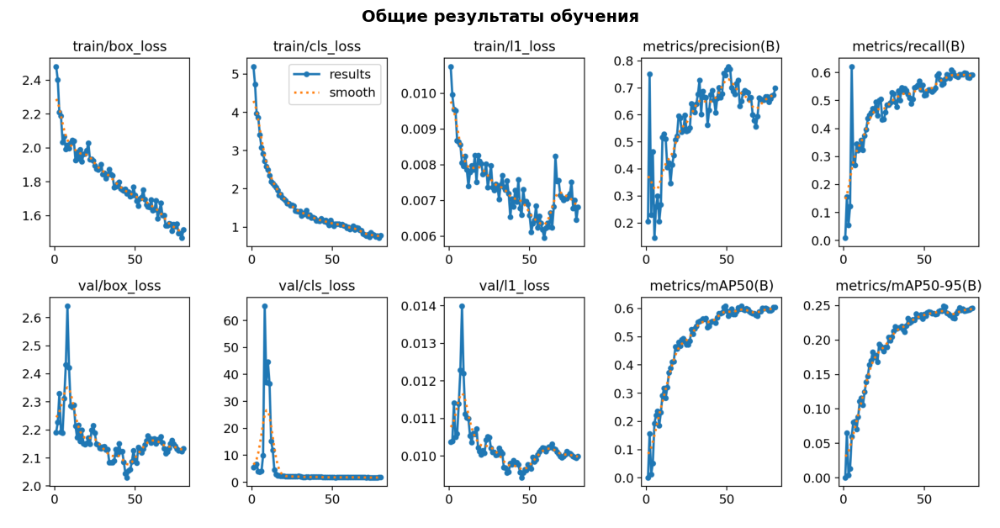

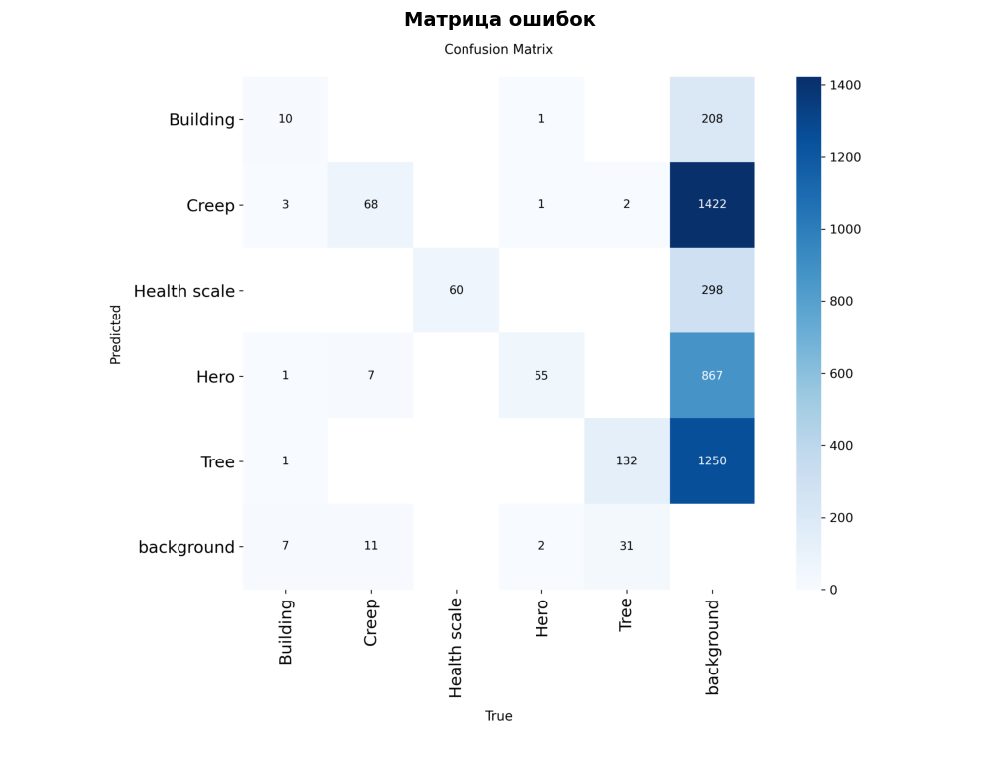

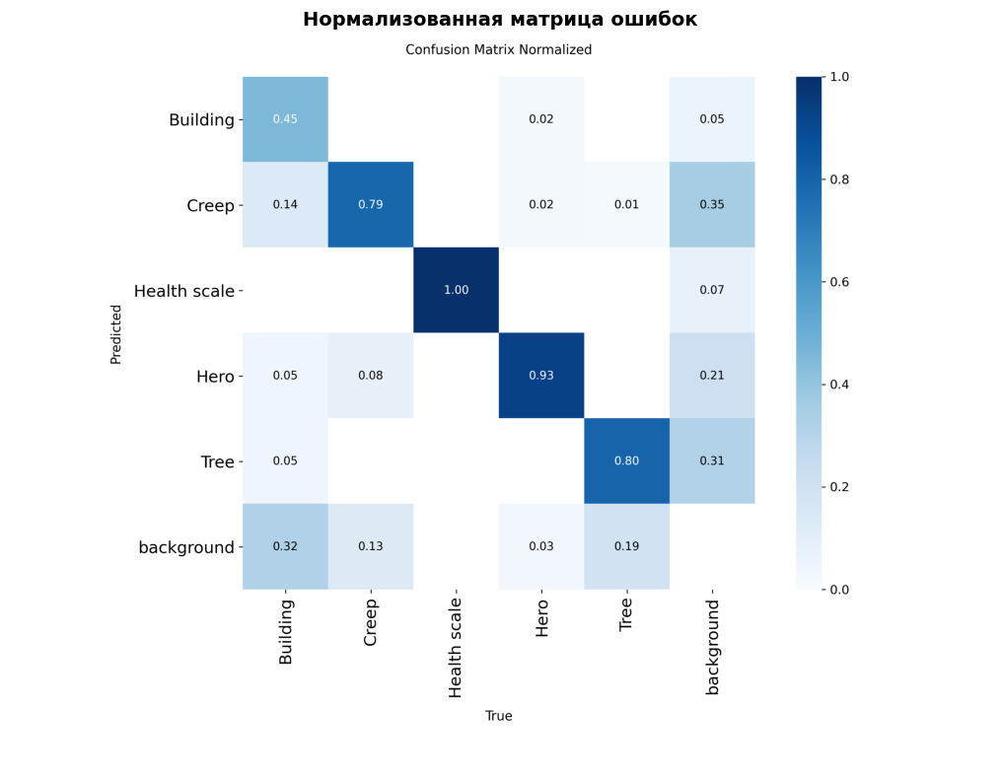

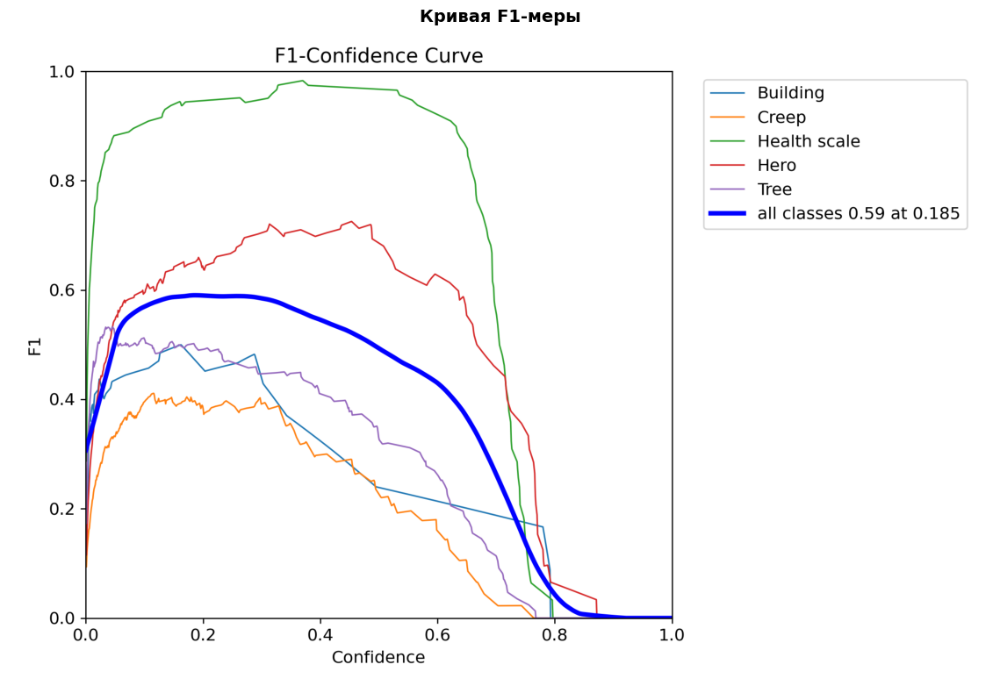

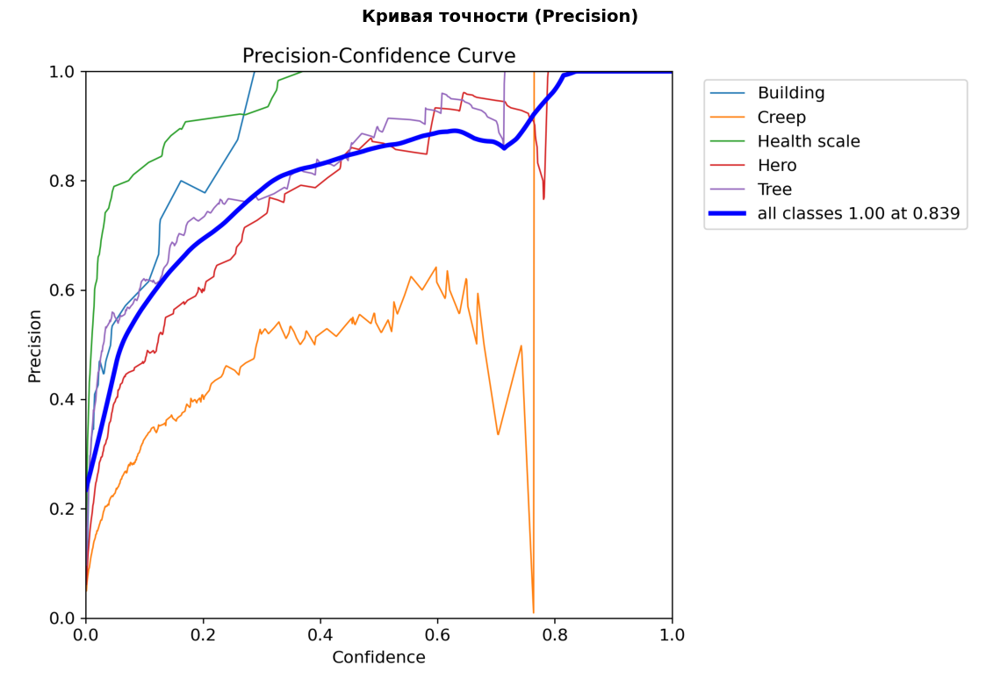

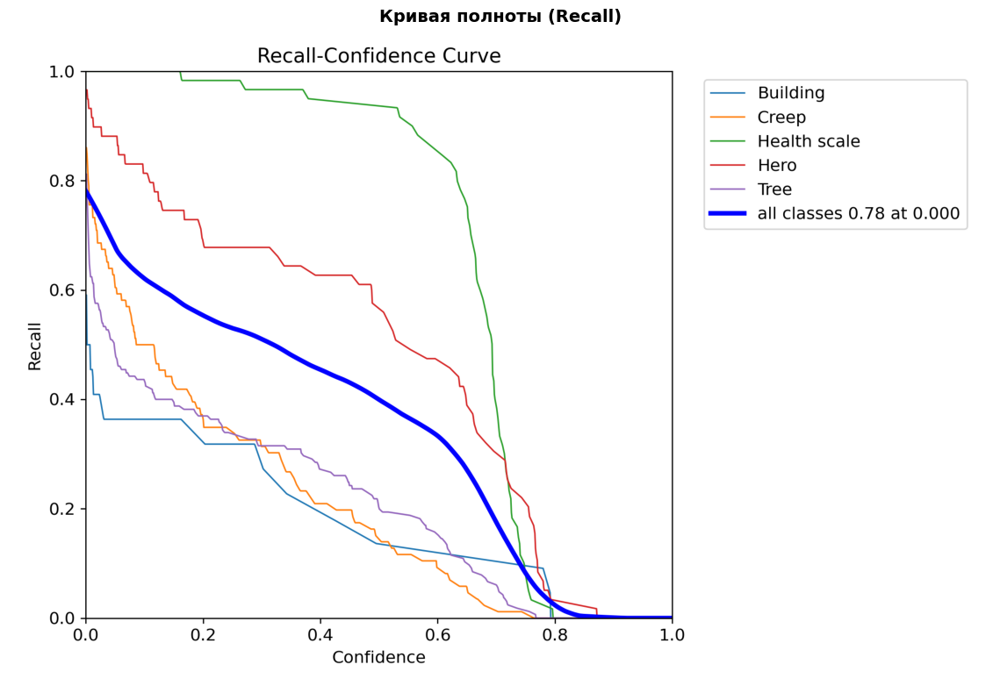

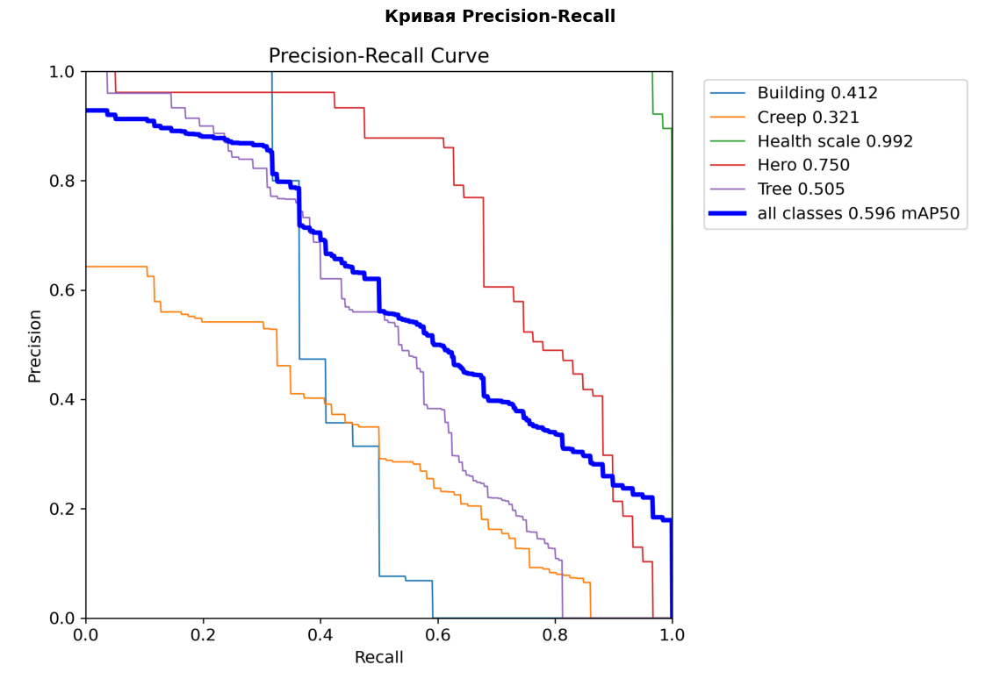

In [13]:
import matplotlib.pyplot as plt
import matplotlib.image as mpimg
from pathlib import Path

def plot_training_results(results_dir):
    """
    Отображает графики метрик обучения.

    Args:
        results_dir: директория с результатами обучения
    """
    results_path = Path(results_dir)

    # Список графиков для отображения
    plots = [
        ('results.png', 'Общие результаты обучения'),
        ('confusion_matrix.png', 'Матрица ошибок'),
        ('confusion_matrix_normalized.png', 'Нормализованная матрица ошибок'),
        ('BoxF1_curve.png', 'Кривая F1-меры'),
        ('BoxP_curve.png', 'Кривая точности (Precision)'),
        ('BoxR_curve.png', 'Кривая полноты (Recall)'),
        ('BoxPR_curve.png', 'Кривая Precision-Recall'),
    ]

    for filename, title in plots:
        filepath = results_path / filename
        if filepath.exists():
            plt.figure(figsize=(12, 8))
            img = mpimg.imread(filepath)
            plt.imshow(img)
            plt.axis('off')
            plt.title(title, fontsize=14, fontweight='bold')
            plt.tight_layout()
            plt.show()
        else:
            print(f"Файл не найден: {filename}")

# Отображение результатов
plot_training_results(results.save_dir)

In [14]:
from ultralytics import YOLO

# Загружаем лучшую модель после обучения
best_model_path = Path(results.save_dir) / 'weights' / 'best.pt'
model = YOLO(best_model_path)

# Параметры валидации
VAL_CONFIG = {
    'data': f"{dataset.location}/data.yaml",
    'imgsz': 640,
    'batch': 32,
    'conf': 0.001,  # Низкий порог для полного анализа
    'iou': 0.7,     # Порог IoU для NMS
    'device': 0,
    'split': 'val',  # Использовать валидационную выборку
    'save_json': True,  # Сохранить результаты в JSON
    'save_hybrid': True,  # Сохранить гибридные метки
    'project': str(RESULTS_DIR),
    'name': 'val_yolo26',
    'exist_ok': True,
}

# Запуск валидации
val_results = model.val(**VAL_CONFIG)

print("\n" + "=" * 50)
print("Результаты валидации:")
print("-" * 50)
print(f"mAP@50:     {val_results.box.map50:.4f}")
print(f"mAP@50:95:  {val_results.box.map:.4f}")
print(f"Precision:  {val_results.box.mp:.4f}")
print(f"Recall:     {val_results.box.mr:.4f}")

WARNING ⚠️ 'save_hybrid' is deprecated and will be removed in the future.
Ultralytics 8.4.211 🚀 Python-3.13.16 torch-2.14.1+cu130 CUDA:0 (Tesla T4, 14913MiB)
YOLO26s summary (fused): 120 layers, 9,467,115 parameters, 0 gradients, 20.8 GFLOPs
val: Fast image access ✅ (ping: 0.0±0.0 ms, read: 1649.8±529.3 MB/s, size: 66.7 KB)
val: Scanning /content/My-First-Project-1/valid/labels.cache... 24 images, 0 backgrounds, 0 corrupt: 100% ━━━━━━━━━━━━ 24/24 5.9Mit/s 0.0s
                 Class     Images  Instances      Box(P          R      mAP50  mAP50-95): 100% ━━━━━━━━━━━━ 1/1 1.3it/s 0.7s
                   all         24        392      0.689      0.567        0.6      0.248
              Building         10         22      0.787      0.337      0.412      0.168
                 Creep         15         86      0.412      0.407      0.339      0.092
          Health scale         23         60      0.924      0.983      0.993      0.469
                  Hero         23         59      0.58

In [15]:
def print_class_metrics(val_results, class_names):
    """
    Выводит метрики качества для каждого класса.

    Args:
        val_results: результаты валидации
        class_names: словарь с именами классов
    """
    print("\nМетрики по классам:")
    print("-" * 70)
    print(f"{'Класс':<20} {'Precision':>10} {'Recall':>10} {'mAP@50':>10} {'mAP@50:95':>10}")
    print("-" * 70)

    # Получаем метрики по классам
    ap50 = val_results.box.ap50
    ap = val_results.box.ap

    for i, class_name in enumerate(class_names.values()):
        if i < len(ap50):
            print(f"{class_name:<20} {'-':>10} {'-':>10} {ap50[i]:>10.4f} {ap[i]:>10.4f}")

    print("-" * 70)
    print(f"{'Среднее':<20} {val_results.box.mp:>10.4f} {val_results.box.mr:>10.4f} {val_results.box.map50:>10.4f} {val_results.box.map:>10.4f}")

# Загружаем имена классов из конфигурации датасета
with open(f"{dataset.location}/data.yaml", 'r') as f:
    data_config = yaml.safe_load(f)

class_names = {i: name for i, name in enumerate(data_config['names'])}
print_class_metrics(val_results, class_names)


Метрики по классам:
----------------------------------------------------------------------
Класс                 Precision     Recall     mAP@50  mAP@50:95
----------------------------------------------------------------------
Building                      -          -     0.4116     0.1682
Creep                         -          -     0.3394     0.0920
Health scale                  -          -     0.9930     0.4689
Hero                          -          -     0.7494     0.2977
Tree                          -          -     0.5065     0.2156
----------------------------------------------------------------------
Среднее                  0.6886     0.5670     0.6000     0.2485


Файл не найден: results.png


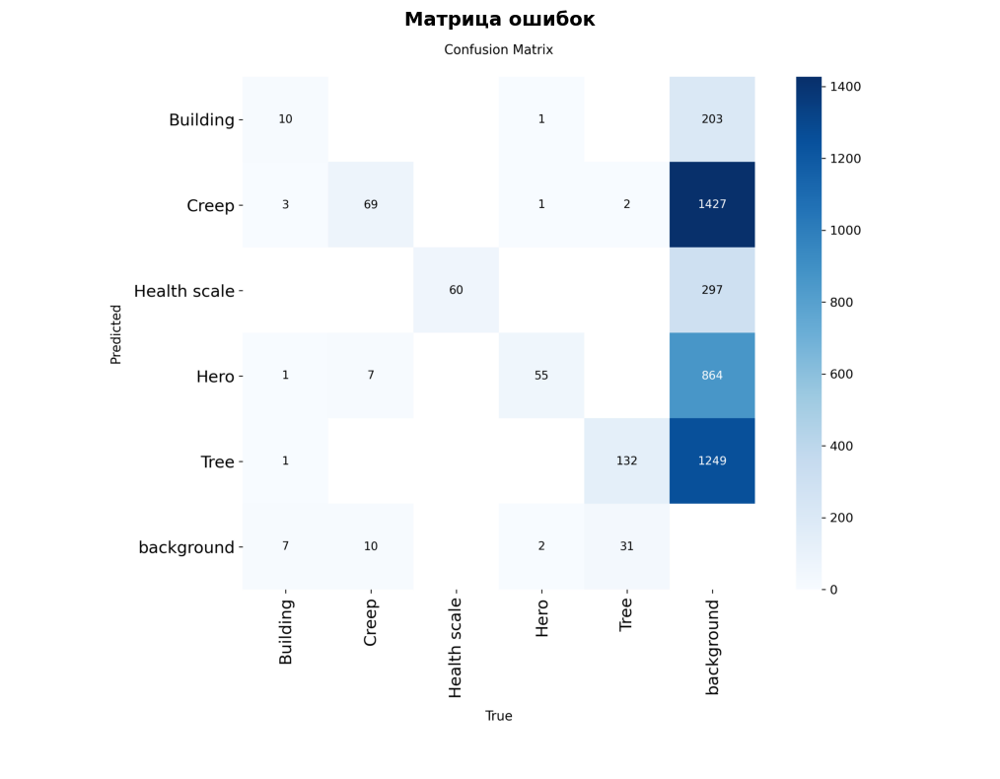

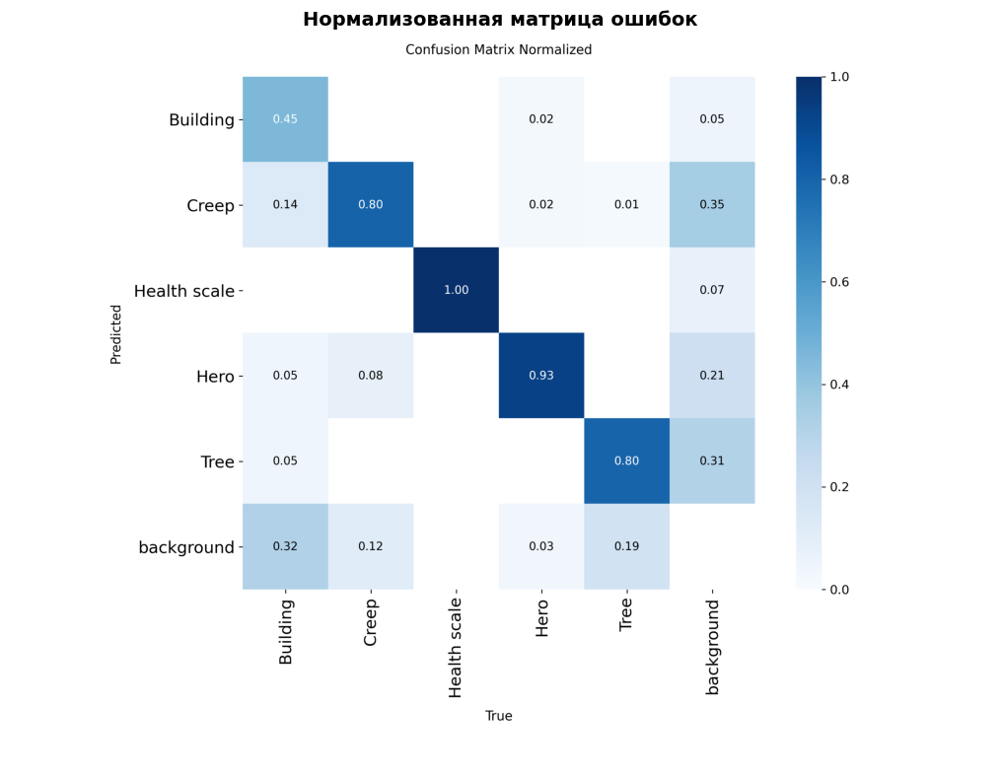

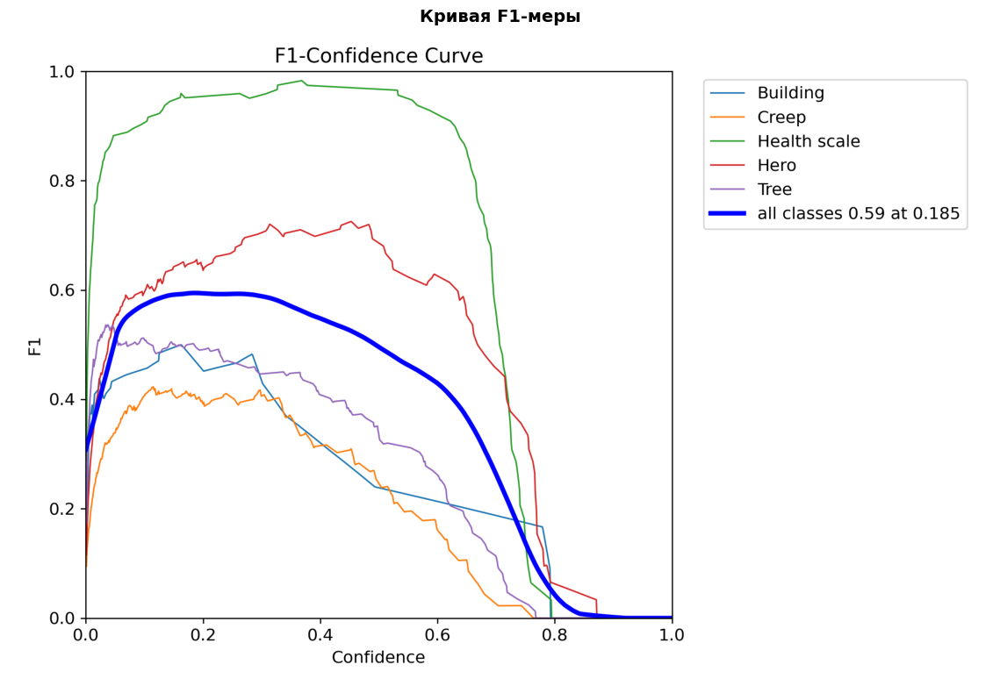

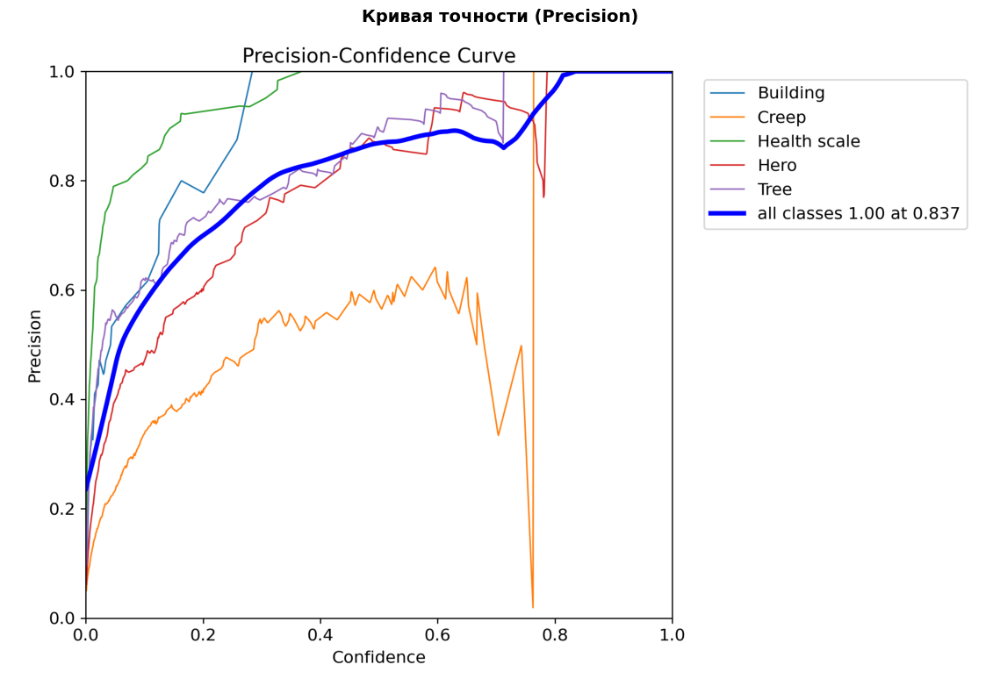

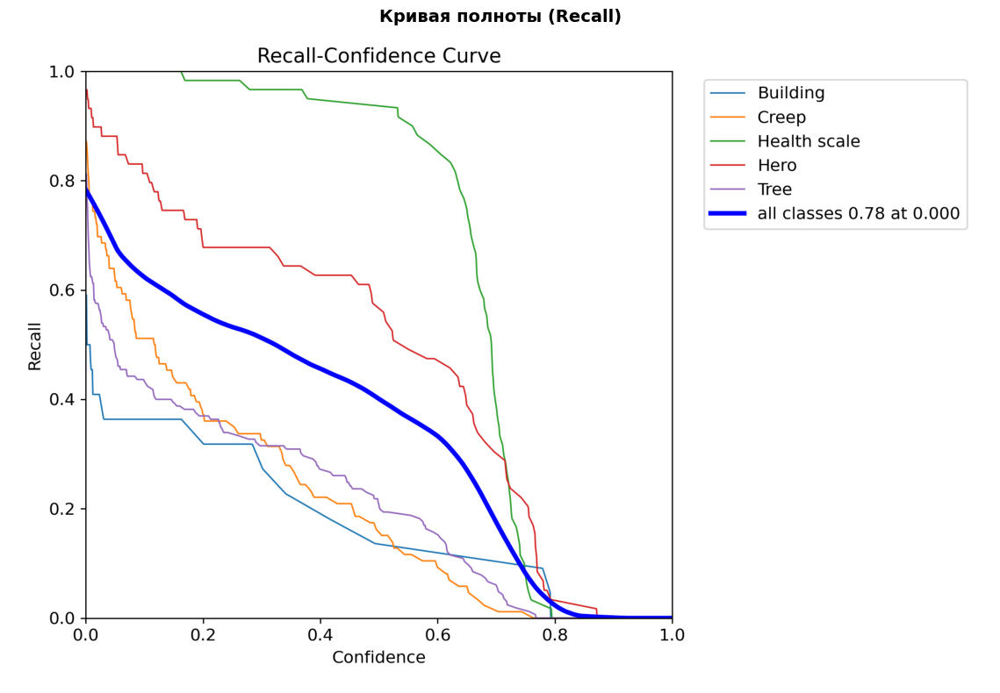

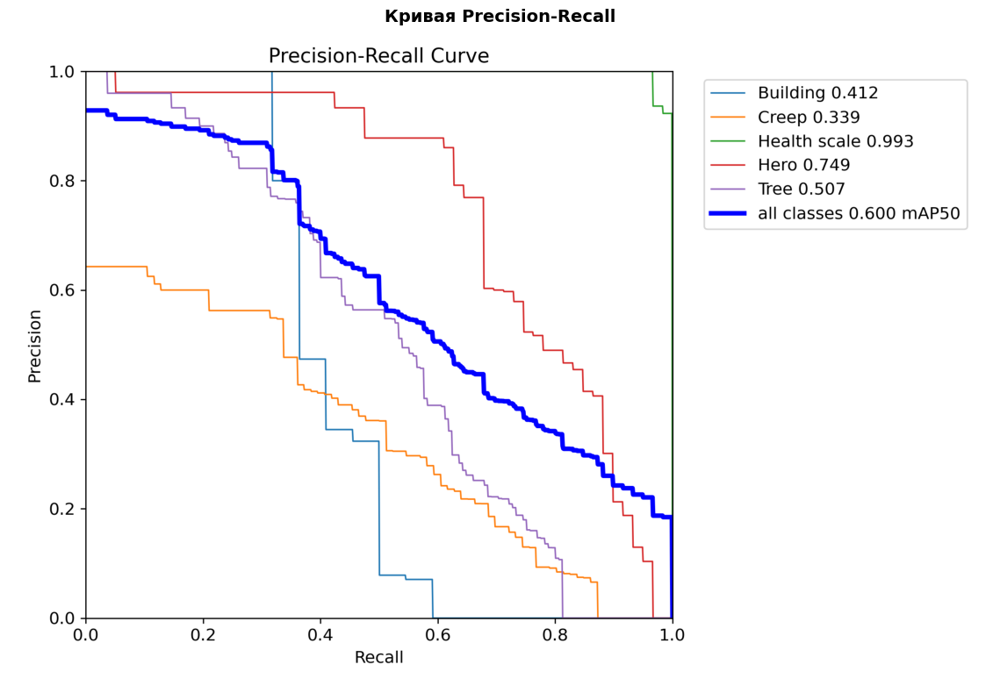

In [16]:
# Отображение графиков валидации
plot_training_results(val_results.save_dir)

In [17]:
from ultralytics import YOLO
from pathlib import Path

# Загрузка обученной модели
best_model_path = Path(results.save_dir) / 'weights' / 'best.pt'
model = YOLO(best_model_path)

# Путь к тестовым изображениям
test_images_path = Path(dataset.location) / 'test' / 'images'

# Параметры инференса
PREDICT_CONFIG = {
    'source': str(test_images_path),
    'imgsz': 640,           # Увеличенный размер для лучшей детекции
    'conf': 0.26,             # Порог уверенности
    'iou': 0.45,             # Порог NMS
    'device': 0,
    'save': True,            # Сохранить изображения с аннотациями
    'save_txt': True,        # Сохранить координаты в текстовые файлы
    'save_conf': True,       # Сохранить уверенность в текстовых файлах
    'project': str(RESULTS_DIR),
    'name': 'predict_yolo26',
    'exist_ok': True,
}

# Запуск предсказаний
predict_results = model.predict(**PREDICT_CONFIG)

print(f"\nРезультаты сохранены в: {RESULTS_DIR / 'predict_yolo26'}")
print(f"Обработано изображений: {len(predict_results)}")


image 1/13 /content/My-First-Project-1/test/images/107_jpg.rf.474ada6ca4dd0b255c8298fd7337416c.jpg: 640x640 1 Building, 1 Health scale, 1 Hero, 15 Trees, 16.5ms
image 2/13 /content/My-First-Project-1/test/images/111_png.rf.91da1d613bf72612105ca39c1527f4e3.jpg: 640x640 1 Creep, 2 Health scales, 1 Hero, 16.5ms
image 3/13 /content/My-First-Project-1/test/images/119_jpg.rf.40dfde026720fcb2bafa90f91d180fc0.jpg: 640x640 6 Health scales, 5 Heros, 6 Trees, 16.6ms
image 4/13 /content/My-First-Project-1/test/images/11_jpg.rf.6f42af40935590f5dd6772c3efab5573.jpg: 640x640 3 Buildings, 4 Creeps, 6 Health scales, 3 Heros, 2 Trees, 16.5ms
image 5/13 /content/My-First-Project-1/test/images/123_webp.rf.fb53b8ed01ca4294b4147cc31493ff86.jpg: 640x640 1 Health scale, 1 Hero, 16.5ms
image 6/13 /content/My-First-Project-1/test/images/14_jpg.rf.e6975c84989a5c759ad2e457fce10fff.jpg: 640x640 1 Building, 2 Creeps, 3 Health scales, 2 Heros, 7 Trees, 16.5ms
image 7/13 /content/My-First-Project-1/test/images/36_jp

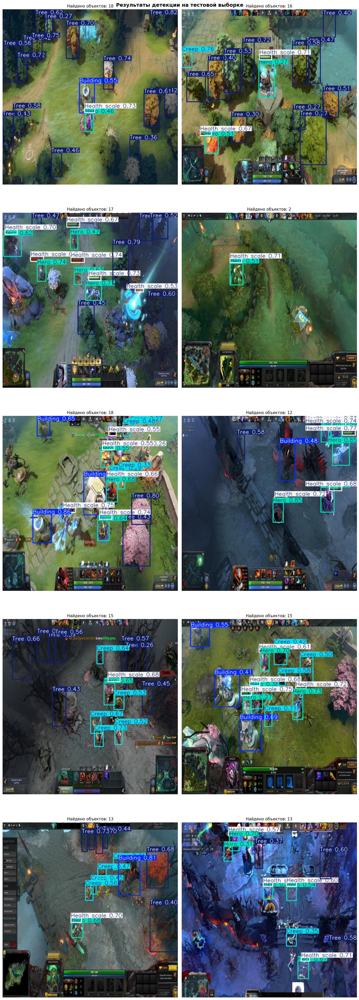

In [18]:
import matplotlib.pyplot as plt
import cv2
import random

def visualize_predictions(results, num_samples=4):
    """
    Отображает результаты детекции на случайных изображениях.

    Args:
        results: список результатов предсказания
        num_samples: количество изображений для отображения
    """
    # Выбираем случайные результаты
    selected = random.sample(results, min(num_samples, len(results)))

    cols = 2
    rows = (num_samples + 1) // 2
    fig, axes = plt.subplots(rows, cols, figsize=(14, 8*rows))
    axes = axes.flatten() if num_samples > 1 else [axes]

    for ax, result in zip(axes, selected):
        # Получаем аннотированное изображение
        annotated = result.plot()
        annotated_rgb = cv2.cvtColor(annotated, cv2.COLOR_BGR2RGB)

        ax.imshow(annotated_rgb)
        ax.set_title(f'Найдено объектов: {len(result.boxes)}', fontsize=11)
        ax.axis('off')

    # Скрываем пустые оси
    for ax in axes[len(selected):]:
        ax.axis('off')

    plt.suptitle('Результаты детекции на тестовой выборке', fontsize=14, fontweight='bold')
    plt.tight_layout()
    plt.show()

visualize_predictions(predict_results, num_samples=10)

Детальный анализ предсказания
Исходное изображение: /content/My-First-Project-1/test/images/119_jpg.rf.40dfde026720fcb2bafa90f91d180fc0.jpg
Размер изображения: (640, 640)
Найдено объектов: 17
------------------------------------------------------------
№    Класс            Уверенность Координаты (x1,y1,x2,y2)
------------------------------------------------------------
1    Tree                 78.77% (402, 116, 461, 261)
2    Hero                 73.78% (127, 190, 158, 251)
3    Health scale         73.65% (250, 164, 298, 182)
4    Health scale         72.64% (314, 230, 360, 249)
5    Health scale         71.18% (103, 160, 149, 179)
6    Hero                 70.70% (303, 266, 362, 322)
7    Health scale         69.67% (8, 63, 53, 80)
8    Health scale         66.81% (235, 35, 281, 53)
9    Hero                 62.72% (261, 217, 290, 264)
10   Hero                 61.85% (3, 83, 68, 160)
11   Tree                 59.88% (531, 306, 586, 393)
12   Health scale         53.02% (484, 278, 

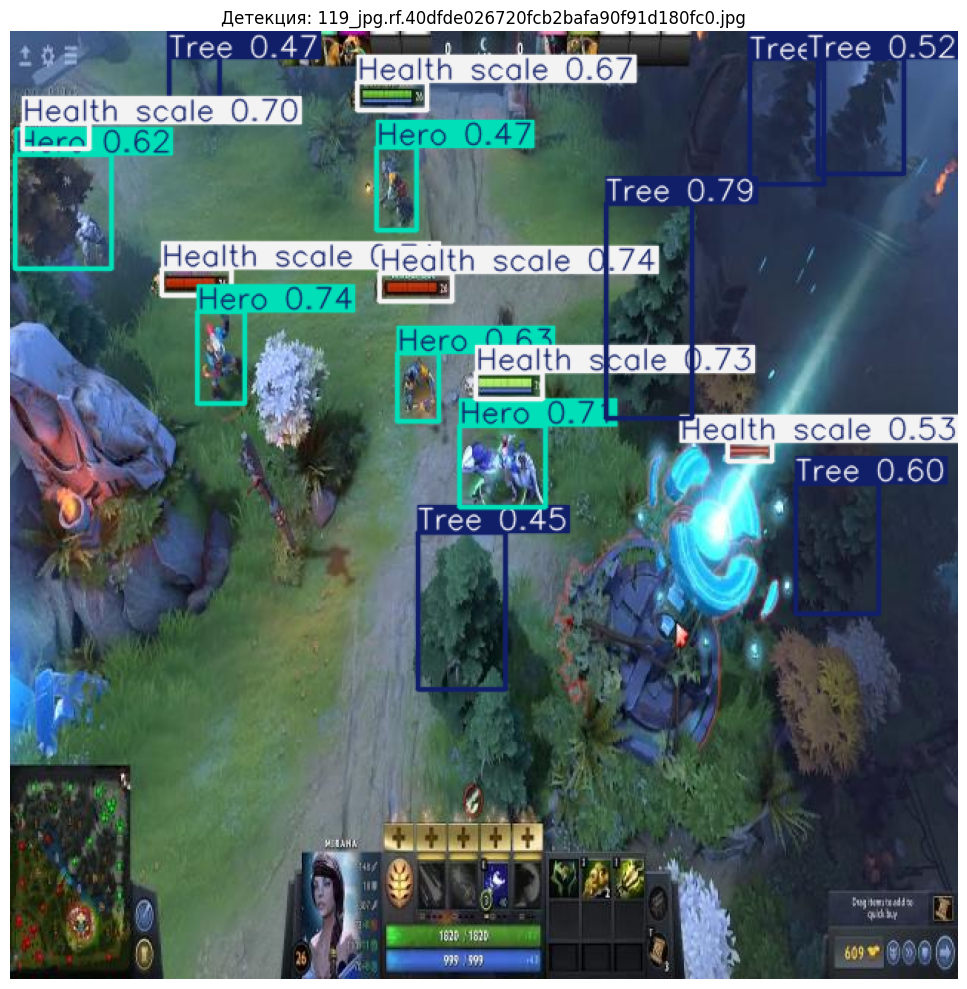

In [23]:
def analyze_single_prediction(result, model):
    """
    Детальный анализ предсказания для одного изображения.

    Args:
        result: результат предсказания
        model: модель YOLO
    """
    print("Детальный анализ предсказания")
    print("=" * 60)
    print(f"Исходное изображение: {result.path}")
    print(f"Размер изображения: {result.orig_shape}")
    print(f"Найдено объектов: {len(result.boxes)}")
    print("-" * 60)

    if len(result.boxes) > 0:
        print(f"{'№':<4} {'Класс':<15} {'Уверенность':>12} {'Координаты (x1,y1,x2,y2)'}")
        print("-" * 60)

        for i, box in enumerate(result.boxes):
            class_id = int(box.cls)
            class_name = model.names[class_id]
            confidence = float(box.conf)
            coords = box.xyxy[0].tolist()
            coords_str = f"({coords[0]:.0f}, {coords[1]:.0f}, {coords[2]:.0f}, {coords[3]:.0f})"

            print(f"{i+1:<4} {class_name:<15} {confidence:>11.2%} {coords_str}")

    # Визуализация
    plt.figure(figsize=(12, 10))
    annotated = result.plot()
    annotated_rgb = cv2.cvtColor(annotated, cv2.COLOR_BGR2RGB)
    plt.imshow(annotated_rgb)
    plt.axis('off')
    plt.title(f'Детекция: {Path(result.path).name}', fontsize=12)
    plt.tight_layout()
    plt.show()

# Анализ первого результата
analyze_single_prediction(predict_results[2], model)


## **Задание 4 (для магистрантов). Обучите модель YOLOv26 на датасете [RSD-GOD](https://github.com/Dr-Zhuang/geospatial-object-detection). Затем самостоятельно сформируйте тестовые данные (не менее 50 изображений с аннотациями) и оцените качество обученной модели:**



**Прямая ссылка на загрузку датасета: [загрузить](https://drive.google.com/open?id=1ttvSta0BRxW7tTV_st89vSb_obHVre34)**

**Ссылка на датасет в среде roboflow universe:** https://universe.roboflow.com/animals-sqrdn/rsd-god

 *Примечание: для поиска данных удобно использовать сервис Google Earth/Google Earth Engine*

In [ ]:
# Ваш код